In [1]:
import pandas as pd
import numpy as np

In [2]:
data = pd.read_csv(r'../data/lambda_0.6_mu_1.0_random.csv')
data

,start_time,total_time,machine_time,machine
0,0.148296,0.175747,0.171821,b149785f78de
1,0.800744,1.703085,1.699203,88e6de608288
2,2.520135,0.308891,0.307129,b149785f78de
3,5.973372,1.127922,1.126139,b149785f78de
4,7.422939,1.086619,1.084408,a120d3fed177
...,...,...,...,...
2983,4977.851771,3.902481,3.649009,88e6de608288
2984,4985.192567,1.913852,1.911881,88e6de608288
2985,4987.655403,1.086788,1.084047,b149785f78de
2986,4988.625526,0.767330,0.765534,a120d3fed177


In [3]:
duration = 5000
initial_time = data['start_time'].min()
final_time = initial_time + duration
data['final_time'] = data['start_time'] + data['total_time']

In [4]:
# utilization X = jobs done / observed time
# basically ammount of rows / duration of experiment
X = (data['final_time'] <= data['start_time'].min() + duration).sum() / duration
X

np.float64(0.5974)

In [5]:
# E[R] average time of response
# Only when the simulation was running
t0 = data['start_time'].min()
completed = data['final_time'] <= t0 + duration
er = data.loc[completed, 'total_time'].mean()
er


np.float64(1.236412569522263)

In [6]:
# E[N] average amount of requests in the system
# Computed by using the start_time and total_time
# using this one can know the amount of requests in the system at any given time
t0 = data['start_time'].min()
t1 = t0 + duration
arrive = data['start_time'].to_numpy()
depart = data['final_time'].to_numpy()
overlap = np.maximum(0.0, np.minimum(depart, t1) - np.maximum(arrive, t0))
en = overlap.sum() / duration
en

np.float64(0.7386328690326007)

In [7]:
# Utilization Ui = machine i used time / total time
machine_ids = {
    name: i
    for i, name in enumerate(sorted(data['machine'].unique()), start=1)
}
data['machine_id'] = data['machine'].map(machine_ids)

t0 = data['start_time'].min()
t1 = t0 + duration
busy_end = data['final_time'].to_numpy()
busy_start = busy_end - data['machine_time'].to_numpy()
data['busy_time'] = np.maximum(
    0.0, np.minimum(busy_end, t1) - np.maximum(busy_start, t0)
)

ui = data.groupby('machine_id')['busy_time'].sum() / duration
print(machine_ids)
ui

{'88e6de608288': 1, 'a120d3fed177': 2, 'b149785f78de': 3}


machine_id
1    0.201683
2    0.194550
3    0.193415
Name: busy_time, dtype: float64

In [8]:
# Little's law verification
# X * E[R] approx E[N]
print(X * er)
print(en)

0.7386328690326
0.7386328690326007


In [12]:
def func(data):
    points = []
    for i in range(1, 5000):
        duration = i
        initial_time = data['start_time'].min()
        final_time = initial_time + duration
        X = (data['final_time'] <= data['start_time'].min() + duration).sum() / duration
        t0 = data['start_time'].min()
        completed = data['final_time'] <= t0 + duration
        er = data.loc[completed, 'total_time'].mean()

        t0 = data['start_time'].min()
        t1 = t0 + duration
        arrive = data['start_time'].to_numpy()
        depart = data['final_time'].to_numpy()
        overlap = np.maximum(0.0, np.minimum(depart, t1) - np.maximum(arrive, t0))
        en = overlap.sum() / duration
        points.append([X, en, er])
    return points

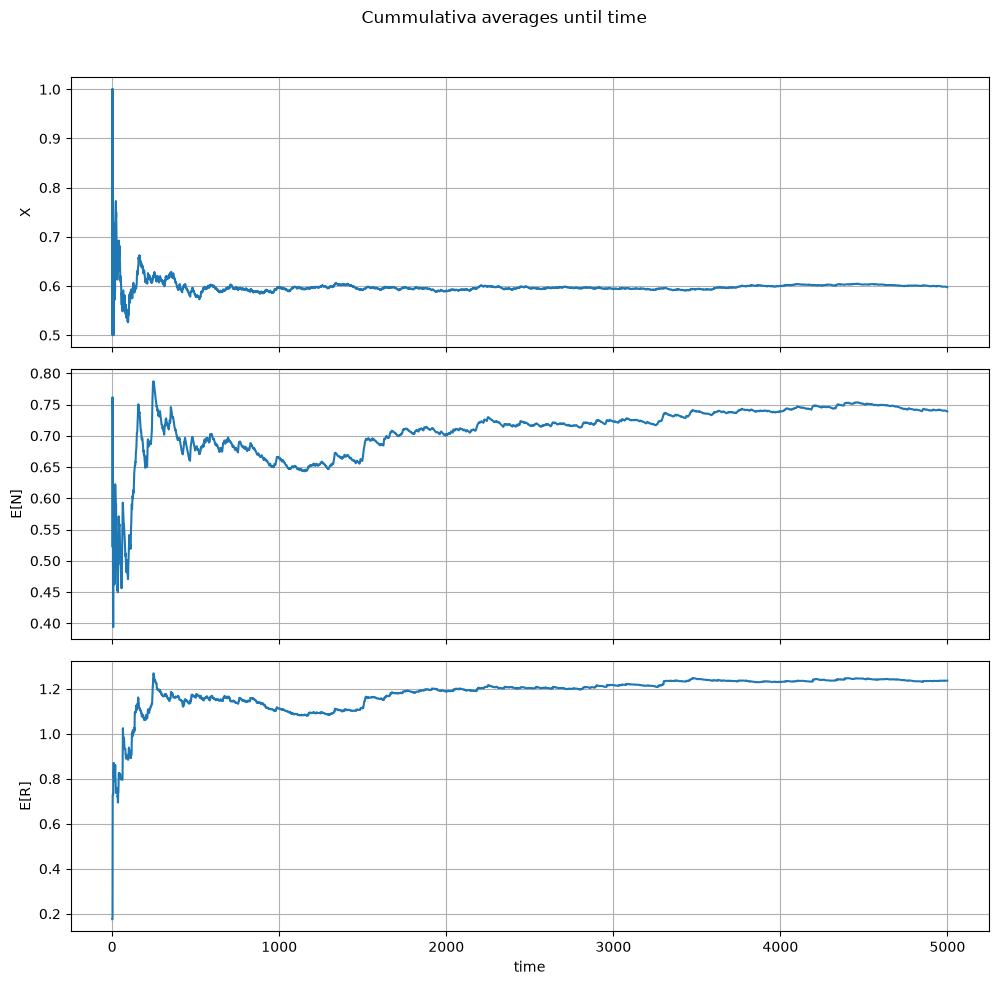

In [13]:
import matplotlib.pyplot as plt

points = np.array(func(data))
i = np.arange(1, len(points) + 1)

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, col, label in zip(axes, range(3), ["X", "E[N]", "E[R]"]):
    ax.plot(i, points[:, col])
    ax.set_ylabel(label)
    ax.grid(True)

axes[-1].set_xlabel("time")
fig.suptitle("Cummulativa averages until time", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

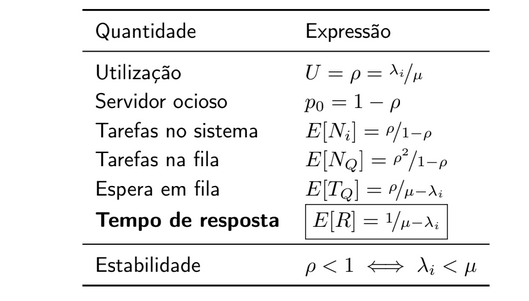

In [15]:
lambdai = 0.6 / 3
mu = 1
rho = lambdai / mu

Eni = rho / (1-rho)
Er = 1/(mu - lambdai)

print(rho, ui)
print(3 * Eni, en)
print(Er, er)

0.19999999999999998 machine_id
1    0.201683
2    0.194550
3    0.193415
Name: busy_time, dtype: float64
0.7499999999999999 0.7386328690326007
1.25 1.236412569522263


In [22]:
lambdai / (1 - lambdai)

0.24999999999999997

In [ ]:
(data['total_time'][data['start_time'] > data['start_time'].min() + warmup_time] - data['machine_time'][data['start_time'] > data['start_time'].min() + warmup_time]).mean()

np.float64(0.2541293595795328)

In [ ]:
X,ER,EN,U1,U2,U3,lambda,mu
0.5995555555555555,1.2443626293621202,0.7451904304275564,0.1990618973333337,0.1958371174515556,0.1979838023135564,0.6,1.0
